# Part 2: washing-machine use in four REFIT homes

Use the **official cleaned** REFIT files to describe washing-machine availability, operating events and usage patterns at one-minute resolution. This notebook covers Part 2 only. Part 1 files are not inputs.

The same period is used for Houses 1, 2, 3 and 5: **1 January to 31 March 2015**, inclusive. These homes have dedicated washing-machine channels in the supplied README. A common three-month period makes the comparison manageable; it is a winter/early-spring snapshot, not a full-year study.

Run cells from top to bottom. All analysis code is here. Required packages: pandas, NumPy, Matplotlib and Jupyter. Outputs go to `outputs/part2/` and `figures/part2/`. Part 1 files are left unchanged.

## 1. Settings and appliance mapping

The official files already contain specialised cleaning, including forward filling. Availability below measures usable values in that release; it cannot recover the freshness of each sensor reading. The README maps House 1 to Appliance5, House 2 to Appliance2, House 3 to Appliance6 and House 5 to Appliance3.

Unix timestamps are interpreted as UTC according to the official cleaned-file documentation. Resampling uses a regular UTC grid. Behavioural charts use **Europe/London local time**, including the March clock change. No raw-data hour correction is applied.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CLEAN_DIR = ROOT / "clean"
OUTPUT_DIR = ROOT / "outputs/part2"
FIGURE_DIR = ROOT / "figures/part2"

WASHING_CHANNELS = {1: "Appliance5", 2: "Appliance2", 3: "Appliance6", 5: "Appliance3"}
START = pd.Timestamp("2015-01-01", tz="UTC")
END = pd.Timestamp("2015-04-01", tz="UTC")  # Exclusive end
LOCAL_TZ = "Europe/London"
MINUTE_GRID = pd.date_range(START, END, freq="1min", inclusive="left")

ACTIVE_W = 20
QUIET_GAP_MINUTES = 10
MIN_ACTIVE_MINUTES = 5
MIN_CYCLE_MINUTES = 10
MAX_CYCLE_MINUTES = 240
MIN_PEAK_W = 500

for house in WASHING_CHANNELS:
    path = CLEAN_DIR / f"CLEAN_House{house}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Missing official cleaned input: {path}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180,
                     "axes.spines.top": False, "axes.spines.right": False})
display(pd.Series(WASHING_CHANNELS, name="washing_machine_channel").rename_axis("house").to_frame())

,washing_machine_channel
house,
1,Appliance5
2,Appliance2
3,Appliance6
5,Appliance3


## 2. Load only the columns and dates needed

Read each CSV in chunks to avoid holding four full-house files in memory. Combine duplicate timestamps using the last non-missing power value; a duplicate is flagged if any record has an issue. Resample valid readings with the arithmetic mean.

The README allows issue discrepancies to be noted rather than discarded. Retain these readings and flag a minute if **any** source record has an issue; report flagged minutes per event. Issue flags compare submeter sums with aggregate and do not by themselves prove the washing-machine channel is invalid. Negative/non-finite values and washing-machine values above the release's 4,000 W screen become missing. No new forward fill or interpolation is performed. Keep sample counts and missing minutes so coverage can be assessed. Minute means are sample-weighted estimates of power; cycle energies are approximate.

In [2]:
def load_house(house, appliance):
    path = CLEAN_DIR / f"CLEAN_House{house}.csv"
    selected = []
    source_rows = 0
    first_unix = None
    last_unix = None
    start_unix = int(START.timestamp())
    end_unix = int(END.timestamp())

    columns = ["Unix", "Aggregate", appliance, "Issues"]
    for chunk in pd.read_csv(path, usecols=columns, chunksize=500_000):
        source_rows += len(chunk)
        first_unix = chunk["Unix"].min() if first_unix is None else min(first_unix, chunk["Unix"].min())
        last_unix = chunk["Unix"].max() if last_unix is None else max(last_unix, chunk["Unix"].max())
        in_period = (chunk["Unix"] >= start_unix) & (chunk["Unix"] < end_unix)
        selected.append(chunk.loc[in_period].copy())

    data = pd.concat(selected, ignore_index=True)
    if data.empty:
        raise ValueError(f"House {house} has no readings in the selected period.")
    period_rows = len(data)
    duplicate_rows = int(data["Unix"].duplicated().sum())
    data = data.rename(columns={appliance: "washing_machine"})
    data = data.sort_values("Unix", kind="stable")
    data = data.groupby("Unix").agg({"Aggregate": "last", "washing_machine": "last", "Issues": "max"})
    data.index = pd.to_datetime(data.index, unit="s", utc=True)
    data.index.name = "timestamp_utc"

    power = data[["Aggregate", "washing_machine"]].astype("float32")
    invalid = power.notna() & ((power < 0) | ~np.isfinite(power))
    invalid["washing_machine"] |= power["washing_machine"] > 4000
    power = power.mask(invalid)
    values = power.resample("1min").mean().reindex(MINUTE_GRID)
    sample_counts = power.resample("1min").count().reindex(MINUTE_GRID, fill_value=0)
    source_counts = data.resample("1min").size().reindex(MINUTE_GRID, fill_value=0)
    issue_minutes = data["Issues"].ne(0).resample("1min").max().reindex(MINUTE_GRID)
    issue_minutes = issue_minutes.eq(True)
    values.index.name = "timestamp_utc"

    audit = {"house": house, "file": path.name, "channel": appliance,
             "source_rows": source_rows,
             "file_start_utc": pd.to_datetime(first_unix, unit="s", utc=True),
             "file_end_utc": pd.to_datetime(last_unix, unit="s", utc=True),
             "period_rows": period_rows, "duplicate_excess_rows": duplicate_rows,
             "first_period_reading_utc": data.index.min(), "last_period_reading_utc": data.index.max(),
             "empty_minute_bins": int((source_counts == 0).sum()),
             "issue_flagged_minutes_retained": int(issue_minutes.sum()),
             "invalid_power_cells": int(invalid.sum().sum())}
    quality = pd.DataFrame({"raw_timestamp_count": source_counts,
                            "issue_flagged": issue_minutes,
                            "washing_valid_samples": sample_counts["washing_machine"],
                            "aggregate_valid_samples": sample_counts["Aggregate"]})
    return values, quality, audit


houses = {}
quality_flags = {}
file_audits = []
for house, appliance in WASHING_CHANNELS.items():
    houses[house], quality_flags[house], audit = load_house(house, appliance)
    file_audits.append(audit)
    print(f"House {house}: {houses[house]['washing_machine'].notna().sum():,} usable washing-machine minutes")

file_audit = pd.DataFrame(file_audits).set_index("house")
display(file_audit)

House 1: 122,876 usable washing-machine minutes


House 2: 124,680 usable washing-machine minutes


House 3: 124,952 usable washing-machine minutes


House 5: 124,852 usable washing-machine minutes


,file,channel,source_rows,file_start_utc,file_end_utc,period_rows,duplicate_excess_rows,first_period_reading_utc,last_period_reading_utc,empty_minute_bins,issue_flagged_minutes_retained,invalid_power_cells
house,,,,,,,,,,,,
1,CLEAN_House1.csv,Appliance5,6960008,2013-10-09 13:06:17+00:00,2015-07-10 11:56:32+00:00,1099370,0,2015-01-01 00:00:01+00:00,2015-03-31 04:22:37+00:00,6724,3036,0
2,CLEAN_House2.csv,Appliance2,5733526,2013-09-17 22:08:11+00:00,2015-05-28 08:05:43+00:00,1107532,0,2015-01-01 00:00:06+00:00,2015-03-31 04:22:37+00:00,4920,1852,0
3,CLEAN_House3.csv,Appliance6,6994594,2013-09-25 19:21:09+00:00,2015-06-02 10:55:42+00:00,1112022,0,2015-01-01 00:00:04+00:00,2015-03-31 04:22:44+00:00,4648,4479,0
5,CLEAN_House5.csv,Appliance3,7430755,2013-09-26 09:56:09+00:00,2015-07-06 17:48:55+00:00,1066310,0,2015-01-01 00:00:01+00:00,2015-03-31 04:22:43+00:00,4748,5725,0


## 3. Define a simple operating-event rule

An active minute has washing-machine mean power **above 20 W**. Active minutes belong to the same event if at most **10 quiet minutes** lie between them. Never join activity across a missing minute.

Keep an event if it has at least **5 active minutes**, spans **10–240 minutes**, and reaches a minute peak of **500 W**. Require 11 usable minutes before and after the event so outage/period boundaries do not create apparently complete cycles.

These are **candidate washing cycles**, not labelled ground truth. The peak screen favours cycles with heating; cold or low-power cycles may be missed. A pause longer than ten minutes can split a cycle, while two close cycles can be merged. Rejected candidates are retained with a reason. We measure the event from its first active minute to its last active minute inclusive, including any short quiet pauses; low-power lead-in/tail time may be omitted.

In [3]:
def detect_cycles(power):
    active = power[power > ACTIVE_W]
    if active.empty:
        return []

    # Missing values divide the signal into separate observed sections.
    observed_section = power.isna().cumsum()
    active_sections = observed_section.loc[active.index]
    gap = active.index.to_series().diff()
    new_event = (gap > pd.Timedelta(minutes=QUIET_GAP_MINUTES + 1)) | active_sections.diff().ne(0)
    event_id = new_event.cumsum()
    rows = []

    for _, event in active.groupby(event_id):
        start = event.index[0]
        last_minute = event.index[-1]
        trace = power.loc[start:last_minute]
        margin = QUIET_GAP_MINUTES + 1
        left = start - pd.Timedelta(minutes=margin)
        right = last_minute + pd.Timedelta(minutes=margin)
        context = power.loc[left:right]
        expected_minutes = len(trace) + 2 * margin
        complete = len(context) == expected_minutes and context.notna().all()

        reason = "accepted"
        if not complete:
            reason = "near missing data or period boundary"
        elif len(event) < MIN_ACTIVE_MINUTES:
            reason = "too few active minutes"
        elif not MIN_CYCLE_MINUTES <= len(trace) <= MAX_CYCLE_MINUTES:
            reason = "duration outside limits"
        elif trace.max() < MIN_PEAK_W:
            reason = "peak below heating screen"

        rows.append({"start_utc": start,
                     "end_utc_exclusive": last_minute + pd.Timedelta(minutes=1),
                     "duration_minutes": len(trace), "active_minutes": len(event),
                     "peak_minute_W": float(trace.max()),
                     "energy_kWh": float(trace.sum() / 60_000),
                     "accepted": reason == "accepted", "reason": reason})
    return rows


# Sanity check the important rule: do not bridge missing data.
example_index = pd.date_range("2015-01-01", periods=80, freq="1min", tz="UTC")
example = pd.Series(0., index=example_index)
example.iloc[15:25] = 1000
example.iloc[30:40] = 1000
assert sum(row["accepted"] for row in detect_cycles(example)) == 1
example.iloc[27] = np.nan
assert not any(row["accepted"] for row in detect_cycles(example))
print("Cycle rule checks passed: short quiet pauses can be joined; missing data cannot.")

candidate_rows = []
for house, values in houses.items():
    for row in detect_cycles(values["washing_machine"]):
        row["house"] = house
        event_flags = quality_flags[house].loc[
            (quality_flags[house].index >= row["start_utc"]) &
            (quality_flags[house].index < row["end_utc_exclusive"]), "issue_flagged"]
        row["issue_flagged_minutes"] = int(event_flags.sum())
        row["issue_flagged_percent"] = 100 * event_flags.mean()
        candidate_rows.append(row)
candidates = pd.DataFrame(candidate_rows)
if candidates.empty:
    raise ValueError("No active events found. Inspect channel mappings and data quality.")
cycles = candidates[candidates["accepted"]].copy()
if cycles.empty:
    raise ValueError("No candidate passes the rule. Review candidates rather than inventing results.")
cycles["start_local"] = cycles["start_utc"].dt.tz_convert(LOCAL_TZ)
cycles["start_hour"] = cycles["start_local"].dt.hour
cycles["start_weekday"] = cycles["start_local"].dt.day_of_week

display(candidates.groupby(["house", "reason"]).size().unstack(fill_value=0))
display(cycles.head())

Cycle rule checks passed: short quiet pauses can be joined; missing data cannot.


reason,accepted,duration outside limits,near missing data or period boundary,peak below heating screen,too few active minutes
house,,,,,
1,59,0,3,3,9
2,63,0,7,0,3
3,98,3,3,4,23
5,87,23,29,12,17


,start_utc,end_utc_exclusive,duration_minutes,active_minutes,peak_minute_W,energy_kWh,accepted,reason,house,issue_flagged_minutes,issue_flagged_percent,start_local,start_hour,start_weekday
0,2015-01-06 03:39:00+00:00,2015-01-06 04:12:00+00:00,33,29,2350.555664,0.396941,True,accepted,1,11,33.333333,2015-01-06 03:39:00+00:00,3,1
1,2015-01-06 10:31:00+00:00,2015-01-06 11:03:00+00:00,32,30,2217.125000,0.337769,True,accepted,1,5,15.625000,2015-01-06 10:31:00+00:00,10,1
4,2015-01-07 03:24:00+00:00,2015-01-07 04:18:00+00:00,54,51,2280.000000,0.566655,True,accepted,1,12,22.222222,2015-01-07 03:24:00+00:00,3,2
5,2015-01-08 04:05:00+00:00,2015-01-08 04:38:00+00:00,33,30,2277.333252,0.341725,True,accepted,1,4,12.121212,2015-01-08 04:05:00+00:00,4,3
6,2015-01-09 04:00:00+00:00,2015-01-09 04:35:00+00:00,35,32,2311.222168,0.344913,True,accepted,1,8,22.857143,2015-01-09 04:00:00+00:00,4,4


## 4. Availability and off/active time

Missing intervals include absent source data and values removed by the numeric checks. REFIT issue flags are retained and reported separately, so they do not create artificial outages. Zero and low/off percentages use **usable washing-machine minutes** as their denominator. “Low/off” means at most 20 W; it includes standby and pauses, so it is not a count of physically switched-off appliances. Missing minutes never count as off.

The cycle count below includes only accepted events with a complete observed context. Cycle counts per observed week adjust for different coverage, but still underestimate activity if excluded periods contain cycles.

In [4]:
availability_rows = []
missing_intervals = []
for house, values in houses.items():
    power = values["washing_machine"]
    valid = power.notna()
    observed_days = valid.sum() / 1440
    # Count whole missing runs, not just individual missing bins.
    missing = power.isna()
    gap_starts = missing & ~missing.shift(fill_value=False)
    gap_ends = missing & ~missing.shift(-1, fill_value=False)
    for start, end in zip(power.index[gap_starts], power.index[gap_ends]):
        missing_intervals.append({"house": house, "start_utc": start,
                                  "end_utc_exclusive": end + pd.Timedelta(minutes=1),
                                  "minutes": int((end - start).total_seconds() / 60) + 1})
    house_cycles = cycles[cycles["house"] == house]
    availability_rows.append({
        "house": house, "period_start_utc": START, "period_end_utc_exclusive": END,
        "expected_minutes": len(power), "usable_washing_minutes": int(valid.sum()),
        "missing_minutes": int(missing.sum()), "missing_runs": int(gap_starts.sum()),
        "usable_percent": round(100 * valid.mean(), 2),
        "zero_percent_of_usable": round(100 * power.eq(0).sum() / valid.sum(), 2) if valid.any() else np.nan,
        "low_off_percent_of_usable": round(100 * power.le(ACTIVE_W).sum() / valid.sum(), 2) if valid.any() else np.nan,
        "active_percent_of_usable": round(100 * power.gt(ACTIVE_W).sum() / valid.sum(), 2) if valid.any() else np.nan,
        "aggregate_usable_percent": round(100 * values["Aggregate"].notna().mean(), 2),
        "accepted_cycles": len(house_cycles),
        "cycles_with_issue_flags": int((house_cycles["issue_flagged_minutes"] > 0).sum()),
        "cycles_per_observed_week": len(house_cycles) / observed_days * 7 if observed_days else np.nan})
availability = pd.DataFrame(availability_rows).set_index("house")
missing_intervals = pd.DataFrame(missing_intervals)
cycle_summary = cycles.groupby("house").agg(
    cycles=("energy_kWh", "size"), median_duration_minutes=("duration_minutes", "median"),
    median_energy_kWh=("energy_kWh", "median"), median_peak_minute_W=("peak_minute_W", "median"),
    median_issue_flagged_percent=("issue_flagged_percent", "median"))
cycle_summary = cycle_summary.reindex(WASHING_CHANNELS)
display(availability)
display(cycle_summary.round(3))

,period_start_utc,period_end_utc_exclusive,expected_minutes,usable_washing_minutes,missing_minutes,missing_runs,usable_percent,zero_percent_of_usable,low_off_percent_of_usable,active_percent_of_usable,aggregate_usable_percent,accepted_cycles,cycles_with_issue_flags,cycles_per_observed_week
house,,,,,,,,,,,,,,
1,2015-01-01 00:00:00+00:00,2015-04-01 00:00:00+00:00,129600,122876,6724,80,94.81,97.63,98.12,1.88,94.81,59,59,4.840001
2,2015-01-01 00:00:00+00:00,2015-04-01 00:00:00+00:00,129600,124680,4920,42,96.20,94.50,95.13,4.87,96.20,63,59,5.093359
3,2015-01-01 00:00:00+00:00,2015-04-01 00:00:00+00:00,129600,124952,4648,29,96.41,92.45,94.00,6.00,96.41,98,97,7.905756
5,2015-01-01 00:00:00+00:00,2015-04-01 00:00:00+00:00,129600,124852,4748,100,96.34,75.73,90.36,9.64,96.34,87,78,7.023996


,cycles,median_duration_minutes,median_energy_kWh,median_peak_minute_W,median_issue_flagged_percent
house,,,,,
1,59,33.0,0.357,2314.100,20.588
2,63,99.0,0.685,2078.111,4.808
3,98,71.5,0.641,1930.056,16.180
5,87,49.0,0.402,2077.333,8.889


## 5. A complete 24-hour example and detected cycles

Select a full 1,440-minute local calendar day with at least 95% usable aggregate and washing-machine minutes, then choose a cycle whose energy is closest to the median among eligible cycles. This gives a typical detected-cycle example on a well-observed day with gaps shown, not a random household-day. The two panels share time so appliance activity can be compared with whole-home demand. Shading marks accepted events; other demand belongs to unmonitored or different appliances.

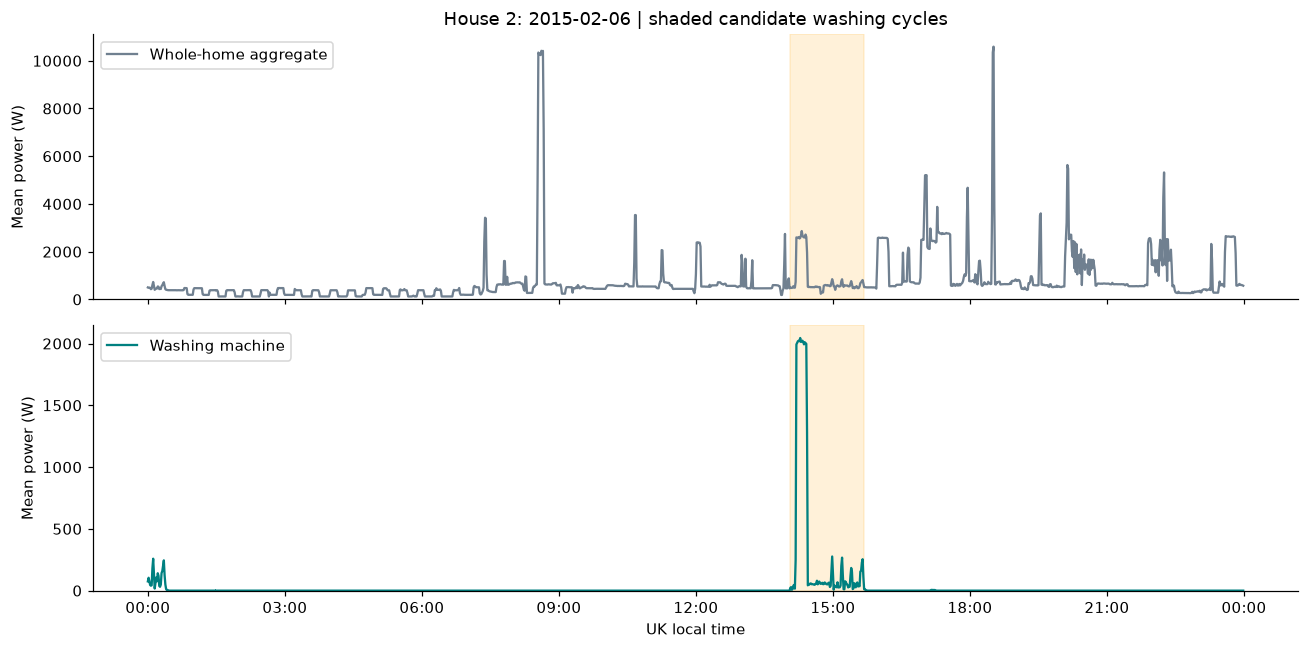

This day has **99.9% joint coverage** and **1 accepted events**. The selected event lasts **97 minutes** and uses approximately **0.59 kWh** within its detected boundaries. The shape alone does not establish the wash programme or load size.

In [5]:
examples = []
for house, values in houses.items():
    complete_minute = values.notna().all(axis=1)
    local_days = values.index.tz_convert(LOCAL_TZ).normalize()
    complete_days = complete_minute.groupby(local_days).sum()
    day_lengths = complete_minute.groupby(local_days).size()
    house_cycles = cycles[cycles["house"] == house]
    for index, row in house_cycles.iterrows():
        day = row["start_local"].normalize()
        # Exclude the short DST day; retain and display any missing minutes.
        if day_lengths.get(day, 0) == 1440 and complete_days.get(day, 0) >= 0.95 * 1440 and row["end_utc_exclusive"].tz_convert(LOCAL_TZ) <= day + pd.DateOffset(days=1):
            examples.append(index)
if not examples:
    raise ValueError("No 24-hour cycle example with at least 95% coverage is available in this period.")
eligible = cycles.loc[examples]
example_cycle = eligible.loc[(eligible["energy_kWh"] - eligible["energy_kWh"].median()).abs().idxmin()]
example_house = int(example_cycle["house"])
example_day = example_cycle["start_local"].normalize()
next_day = example_day + pd.DateOffset(days=1)
local_values = houses[example_house].tz_convert(LOCAL_TZ)
day_trace = local_values.loc[(local_values.index >= example_day) & (local_values.index < next_day)]
day_cycles = cycles[(cycles["house"] == example_house) &
                    (cycles["start_local"] >= example_day) & (cycles["start_local"] < next_day)]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(day_trace.index, day_trace["Aggregate"], color="slategray", label="Whole-home aggregate")
axes[1].plot(day_trace.index, day_trace["washing_machine"], color="teal", label="Washing machine")
for _, row in day_cycles.iterrows():
    for ax in axes:
        ax.axvspan(row["start_local"], row["end_utc_exclusive"].tz_convert(LOCAL_TZ), color="orange", alpha=0.15)
for ax in axes:
    ax.set_ylabel("Mean power (W)")
    ax.legend(loc="upper left")
    ax.set_ylim(bottom=0)
axes[0].set_title(f"House {example_house}: {example_day.date()} | shaded candidate washing cycles")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=LOCAL_TZ))
axes[1].set_xlabel("UK local time")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "representative_24h.png", bbox_inches="tight")
plt.show()
display(Markdown(f"This day has **{100 * day_trace.notna().all(axis=1).mean():.1f}% joint coverage** and **{len(day_cycles)} accepted events**. The selected event lasts **{example_cycle['duration_minutes']:.0f} minutes** and uses approximately **{example_cycle['energy_kWh']:.2f} kWh** within its detected boundaries. The shape alone does not establish the wash programme or load size."))

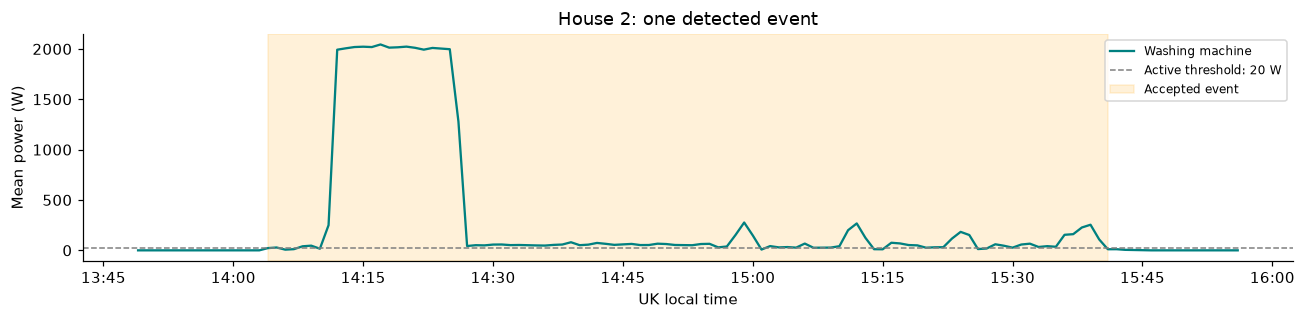

Short quiet pauses inside the shaded interval are included in the event. Its boundaries are the first and last active minutes, not independently labelled machine start/finish times.

In [6]:
# A close-up shows the detected boundaries and quiet pauses.
start = example_cycle["start_local"]
end = example_cycle["end_utc_exclusive"].tz_convert(LOCAL_TZ)
trace = local_values.loc[start - pd.Timedelta(minutes=15):end + pd.Timedelta(minutes=15)]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(trace.index, trace["washing_machine"], color="teal", label="Washing machine")
ax.axhline(ACTIVE_W, color="gray", linestyle="--", linewidth=1, label=f"Active threshold: {ACTIVE_W} W")
ax.axvspan(start, end, color="orange", alpha=0.15, label="Accepted event")
ax.set(title=f"House {example_house}: one detected event", ylabel="Mean power (W)", xlabel="UK local time")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=LOCAL_TZ))
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "detected_cycle_example.png", bbox_inches="tight")
plt.show()
display(Markdown("Short quiet pauses inside the shaded interval are included in the event. Its boundaries are the first and last active minutes, not independently labelled machine start/finish times."))

## 6. Hour-of-day and weekday patterns

Use event **start times** in UK local time. Normalise by usable washing-machine exposure in each hour/weekday so unequal missing data do not automatically look like lower use. This still assumes usable periods reasonably reflect missing periods, and the complete-event requirement can remove additional events around outages.

Hourly rates mean starts per 100 observed hours of that clock hour. Weekday rates mean starts per 24 observed hours occurring on that weekday. The plots describe associations in these four homes, not population habits.

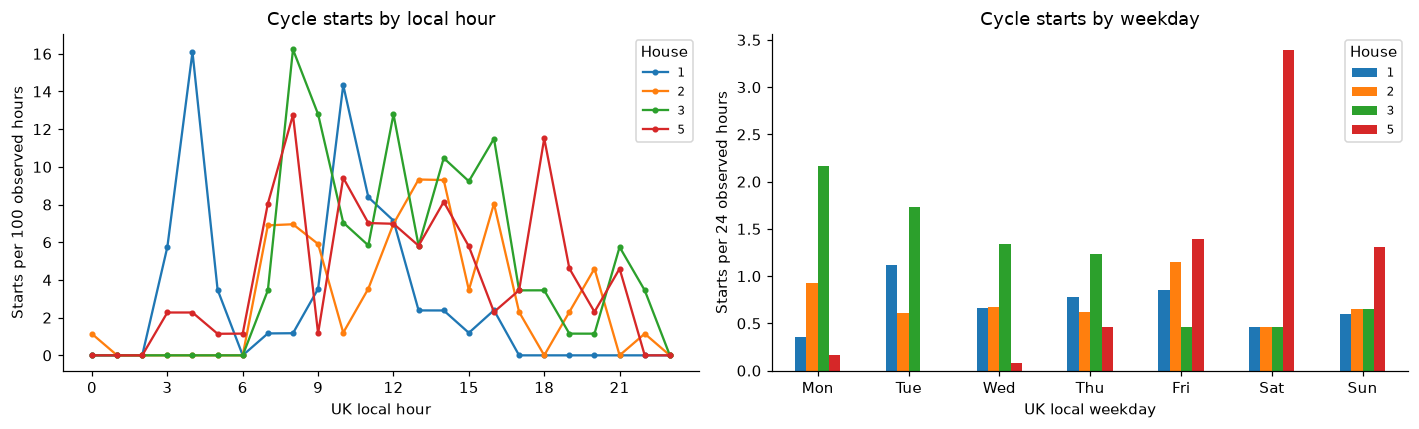

Across the selected homes, the largest pooled start rate is at **08:00** and on **Saturday**. Household curves should also be inspected: the pooled peak can be influenced by a home with more events, and does not imply every home follows the same schedule.

In [7]:
hourly_rows = []
weekday_rows = []
for house, values in houses.items():
    local_power = values["washing_machine"].tz_convert(LOCAL_TZ)
    valid = local_power.notna()
    hour_minutes = valid.groupby(valid.index.hour).sum().reindex(range(24), fill_value=0)
    weekday_minutes = valid.groupby(valid.index.day_of_week).sum().reindex(range(7), fill_value=0)
    house_cycles = cycles[cycles["house"] == house]
    hour_starts = house_cycles["start_hour"].value_counts().reindex(range(24), fill_value=0)
    weekday_starts = house_cycles["start_weekday"].value_counts().reindex(range(7), fill_value=0)
    for hour in range(24):
        hours = hour_minutes.loc[hour] / 60
        hourly_rows.append({"house": house, "hour": hour, "starts": int(hour_starts.loc[hour]),
                            "observed_hours": hours,
                            "starts_per_100_observed_hours": 100 * hour_starts.loc[hour] / hours if hours else np.nan})
    for weekday in range(7):
        days = weekday_minutes.loc[weekday] / 1440
        weekday_rows.append({"house": house, "weekday": weekday, "starts": int(weekday_starts.loc[weekday]),
                             "observed_24h_equivalents": days,
                             "starts_per_24_observed_hours": weekday_starts.loc[weekday] / days if days else np.nan})
hourly = pd.DataFrame(hourly_rows)
weekday = pd.DataFrame(weekday_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hourly.pivot(index="hour", columns="house", values="starts_per_100_observed_hours").plot(ax=axes[0], marker="o", markersize=3)
weekday.pivot(index="weekday", columns="house", values="starts_per_24_observed_hours").plot.bar(ax=axes[1])
axes[0].set(title="Cycle starts by local hour", xlabel="UK local hour", ylabel="Starts per 100 observed hours")
axes[0].set_xticks(range(0, 24, 3))
axes[1].set(title="Cycle starts by weekday", xlabel="UK local weekday", ylabel="Starts per 24 observed hours")
axes[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
for ax in axes:
    ax.legend(title="House", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hour_and_weekday_patterns.png", bbox_inches="tight")
plt.show()
# Pool counts and exposure for a descriptive summary, not an average of household rates.
pooled_hours = hourly.groupby("hour")[["starts", "observed_hours"]].sum()
pooled_hour_rate = 100 * pooled_hours["starts"] / pooled_hours["observed_hours"]
pooled_days = weekday.groupby("weekday")[["starts", "observed_24h_equivalents"]].sum()
pooled_day_rate = pooled_days["starts"] / pooled_days["observed_24h_equivalents"]
week_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
display(Markdown(f"Across the selected homes, the largest pooled start rate is at **{pooled_hour_rate.idxmax():02d}:00** and on **{week_names[pooled_day_rate.idxmax()]}**. Household curves should also be inspected: the pooled peak can be influenced by a home with more events, and does not imply every home follows the same schedule."))

## 7. Compare cycle characteristics across homes

Compare duration and estimated energy distributions rather than just total consumption. Different machines, programmes, loads, flagged discrepancies and event-detection errors can explain differences. The boxes describe accepted complete candidates only; they do not establish efficiency rankings.

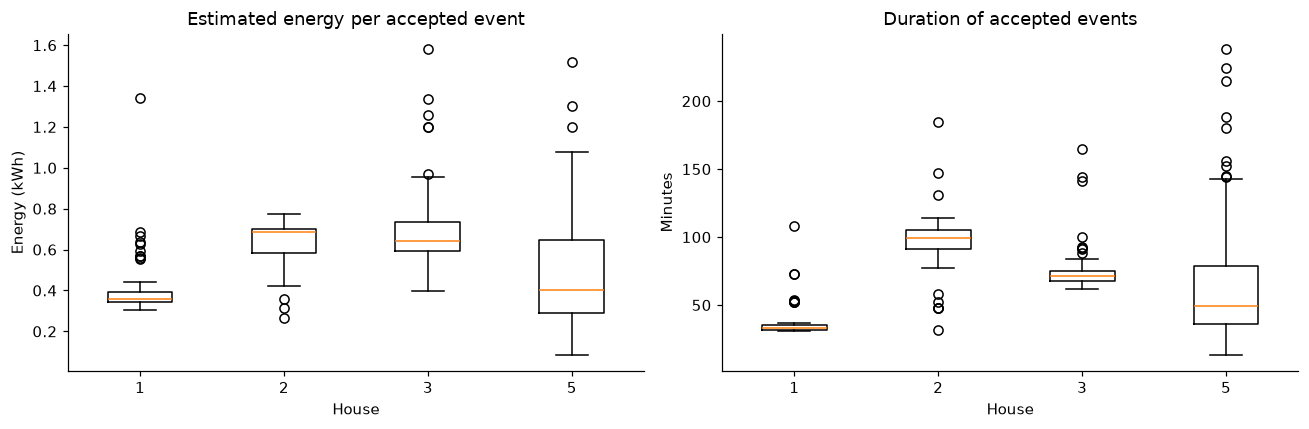

,cycles,median_duration_minutes,median_energy_kWh,median_peak_minute_W,median_issue_flagged_percent
house,,,,,
1,59,33.0,0.357,2314.100,20.588
2,63,99.0,0.685,2078.111,4.808
3,98,71.5,0.641,1930.056,16.180
5,87,49.0,0.402,2077.333,8.889


House **1** has the lowest detected median event energy and House **2** the highest in this window. This comparison is conditional on the rule, usable data and selected quarter; without programme/load information it is not a measured appliance-efficiency comparison.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
house_order = list(WASHING_CHANNELS)
energy_groups = [cycles.loc[cycles["house"] == house, "energy_kWh"].values for house in house_order]
duration_groups = [cycles.loc[cycles["house"] == house, "duration_minutes"].values for house in house_order]
axes[0].boxplot(energy_groups, tick_labels=house_order)
axes[1].boxplot(duration_groups, tick_labels=house_order)
axes[0].set(title="Estimated energy per accepted event", ylabel="Energy (kWh)", xlabel="House")
axes[1].set(title="Duration of accepted events", ylabel="Minutes", xlabel="House")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cross_house_cycle_comparison.png", bbox_inches="tight")
plt.show()
display(cycle_summary.round(3))
lowest = cycle_summary["median_energy_kWh"].idxmin()
highest = cycle_summary["median_energy_kWh"].idxmax()
display(Markdown(f"House **{lowest}** has the lowest detected median event energy and House **{highest}** the highest in this window. This comparison is conditional on the rule, usable data and selected quarter; without programme/load information it is not a measured appliance-efficiency comparison."))

## 8. Validate and save

Check a regular grid for every home, consistent missing/active/off counts, event durations and energy units, and absence of missing values inside accepted events. Save small audit and event tables; the minute-level power files are compressed. No Part 1 output is overwritten.

In [9]:
assert len(houses) >= 4
for house, values in houses.items():
    assert values.index.equals(MINUTE_GRID)
    assert values.index.is_unique and values.index.is_monotonic_increasing
    assert not values.isin([np.inf, -np.inf]).any().any()
    assert not (values < 0).any().any()
    row = availability.loc[house]
    assert row["usable_washing_minutes"] + row["missing_minutes"] == len(MINUTE_GRID)
    assert missing_intervals.loc[missing_intervals["house"] == house, "minutes"].sum() == row["missing_minutes"]
for row in cycles.itertuples():
    power = houses[row.house]["washing_machine"]
    trace = power.loc[(power.index >= row.start_utc) & (power.index < row.end_utc_exclusive)]
    assert trace.notna().all()
    assert len(trace) == row.duration_minutes
    assert np.isclose(trace.sum() / 60_000, row.energy_kWh)
    assert MIN_CYCLE_MINUTES <= row.duration_minutes <= MAX_CYCLE_MINUTES
assert cycles.groupby("house").size().reindex(availability.index, fill_value=0).equals(availability["accepted_cycles"])

missing_intervals.to_csv(OUTPUT_DIR / "missing_intervals.csv", index=False)
file_audit.to_csv(OUTPUT_DIR / "source_file_audit.csv")
availability.to_csv(OUTPUT_DIR / "availability_summary.csv")
candidates.to_csv(OUTPUT_DIR / "cycle_candidates.csv", index=False)
cycles.to_csv(OUTPUT_DIR / "detected_cycles.csv", index=False)
cycle_summary.to_csv(OUTPUT_DIR / "cycle_summary.csv")
hourly.to_csv(OUTPUT_DIR / "hourly_start_rates.csv", index=False)
weekday.to_csv(OUTPUT_DIR / "weekday_start_rates.csv", index=False)
for house, values in houses.items():
    values.to_csv(OUTPUT_DIR / f"house{house}_1min.csv.gz", compression={"method": "gzip", "mtime": 0})
    quality_flags[house].to_csv(OUTPUT_DIR / f"house{house}_quality.csv.gz", compression={"method": "gzip", "mtime": 0})
print("Validation passed. Part 2 tables and figures saved.")

Validation passed. Part 2 tables and figures saved.


## 9. Interpretation and limits

Cycle detection is rule-based: unknown programmes, long pauses and cold washes can lead to missed or split events. Close events may merge. Issue-flagged readings are retained with explicit event-level counts; their aggregate/submeter discrepancy remains a limitation. Excluding incomplete candidates can bias usage patterns toward reliable periods. Source forward-filling cannot be undone from the cleaned data alone. Minute averaging reduces switching peaks, and reported cycle energy is an approximate sum of sample-weighted minute power.

The common period, channel mapping, quality counts and rule parameters are explicit. Comparisons describe these four households during the selected quarter. They do not generalise to all UK households or establish causal effects. This notebook does not train a disaggregation model.

Sources: supplied assignment and cleaned REFIT README. REFIT dataset licence: CC BY 4.0 according to the supplied notes. See the official [dataset page](https://pureportal.strath.ac.uk/en/datasets/refit-electrical-load-measurements/) for attribution. OpenAI Codex assisted with implementation and execution; findings below are calculated from the local data.

In [10]:
def markdown_table(table):
    text = "| " + " | ".join(str(c) for c in table.columns) + " |\n"
    text += "| " + " | ".join("---" for c in table.columns) + " |\n"
    for row in table.itertuples(index=False, name=None):
        text += "| " + " | ".join(str(value) for value in row) + " |\n"
    return text

quality_table = availability[["usable_percent", "zero_percent_of_usable", "low_off_percent_of_usable",
                              "missing_minutes", "accepted_cycles", "cycles_with_issue_flags", "cycles_per_observed_week"]].round(2).reset_index()
report = f"""# Part 2 results: washing-machine use

Generated by `WashingMachine_Part2_EDA.ipynb`. This section contains Part 2 findings.

## Data and method
Official cleaned Houses 1, 2, 3 and 5, with washing-machine channels {WASHING_CHANNELS}. The common window is {START} to {END} exclusive (January-March 2015). Resampling uses UTC; behavioural charts use Europe/London time. The source-file audit records full file coverage, selected rows and issue-flagged minutes. Issue-flagged readings are retained, with per-event counts as permitted by the README; no new interpolation is used. Published forward filling limits interpretation of sensor availability.

{markdown_table(quality_table)}

Zero/off percentages use only usable minute values. Low/off means <= {ACTIVE_W} W, not confirmed switched-off time. Missing readings do not count as off. Rates per observed week adjust for exposure but not non-random missingness.

## Event rule
Active mean power > {ACTIVE_W} W; join active minutes across at most {QUIET_GAP_MINUTES} quiet minutes, never through missing data. Accept >= {MIN_ACTIVE_MINUTES} active minutes, duration {MIN_CYCLE_MINUTES}-{MAX_CYCLE_MINUTES} minutes and peak >= {MIN_PEAK_W} W. Require {QUIET_GAP_MINUTES+1} observed minutes on both sides. These are candidate complete events, not labelled true cycles. Cold washes and long pauses can be missed or split; nearby cycles can merge.

Detected {len(cycles)} accepted events. **{int((cycles['issue_flagged_minutes'] > 0).sum())} events contain at least one REFIT issue-flagged minute**; the median event has {cycles['issue_flagged_percent'].median():.1f}% flagged minutes. The per-house median flagged percentage is reported below. These discrepancies reduce confidence in exact aggregate/submeter consistency and energy estimates; retaining them is an explicit exploratory choice, not a claim that the flags are resolved. Filtering every flagged minute fragmented most events in an initial diagnostic, so the final rule retains them with transparent flags as allowed by the README.

Energy is sum of minute power divided by 60,000, in kWh; duration includes short internal pauses and excludes unobserved/low-power tails. Peaks refer to minute means.

{markdown_table(cycle_summary.round(3).reset_index())}

## Plots and interpretation
![Example day](figures/part2/representative_24h.png)
House {example_house}, {example_day.date()}, chosen from 24-hour local days with at least 95% joint coverage with a median-energy candidate event. Shading shows accepted events alongside aggregate demand; this day has {100 * day_trace.notna().all(axis=1).mean():.1f}% joint coverage and missing values remain blank. This is an illustrative day, not a random sample.

![Cycle](figures/part2/detected_cycle_example.png)
The selected event lasts {example_cycle['duration_minutes']:.0f} minutes and contains approximately {example_cycle['energy_kWh']:.2f} kWh. Boundaries depend on the active-power rule; no appliance programme labels are available.

![Start patterns](figures/part2/hour_and_weekday_patterns.png)
Largest pooled exposure-adjusted start rates occur at {pooled_hour_rate.idxmax():02d}:00 UK local time and on {week_names[pooled_day_rate.idxmax()]}. Per-house curves show differences; pooled peaks need not describe every home. Hourly rates are starts per 100 observed clock-hours; weekday rates are starts per 24 observed hours on that weekday.

![Cross-house comparison](figures/part2/cross_house_cycle_comparison.png)
House {lowest} has the lowest detected median event energy and House {highest} the highest in this period. Programme, load, machine and detection differences prevent an efficiency ranking.

## Validation and limitations
Passed: four homes, regular unique minute grids, issue-flag reporting, non-negative finite available values, reconciled availability, event counts and event energy/duration calculations. The synthetic pause/missing-data check passed. Exact event truth, cycle recall, programme/load characteristics and source sensor freshness remain unknown. Missingness and complete-event filtering can bias behaviour comparisons. The results cover one winter/early-spring quarter and four selected homes.

All event/candidate tables, exact missing-interval ranges, quality summaries and exposure denominators are in `outputs/part2/`. Rejected candidates include reasons. No Part 1 files are used or changed; no model is trained. Dataset attribution: REFIT, University of Strathclyde, with CC BY 4.0 per the supplied README. AI assistance: OpenAI Codex; numerical findings are from the executed notebook.
"""
# Update Part 2 while preserving Part 3
results_path = ROOT / "RESULTS.md"
marker = "<!-- PART3_START -->"

part3_section = ""

if results_path.exists():
    existing = results_path.read_text(encoding="utf-8")

    if marker in existing:
        part3_section = existing[existing.index(marker):]
    elif "# Part 3" in existing:
        raise ValueError("Part 3 exists without a section marker.")

updated_report = report.rstrip() + "\n"

if part3_section:
    updated_report += "\n" + part3_section

results_path.write_text(updated_report, encoding="utf-8")

print("RESULTS.md updated. Existing Part 3 preserved.")

RESULTS.md updated. Existing Part 3 preserved.
